In [1]:
import datetime
import os

import laspy
import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d
import torch
import geopandas as gpd
import py4dgeo

import pipeline

In [5]:
%pip install plyfile

Note: you may need to restart the kernel to use updated packages.


cloud1_transform:
0.016997808591 -0.006867627613 -0.002250073710 61.350204467773
-0.006642486434 -0.012581477873 -0.011778643355 815.083801269531
-0.002846842399 -0.011648809537 0.014048252255 1039.387695312500
0.000000000000 0.000000000000 0.000000000000 1.000000000000

cloud4_t:
-0.014011225663 0.004350652453 -0.011145155877 53.568080902100
0.010189454071 -0.004655822180 -0.014627216384 788.437316894531
0.006270382553 0.017287345603 -0.001134529477 1048.019042968750
0.000000000000 0.000000000000 0.000000000000 1.000000000000

### Debuging Parameters

In [2]:
log_dir = f"outputs/{datetime.datetime.now().strftime('%Y%m%d-%H%M')}"
nth = 1

os.makedirs(log_dir, exist_ok=True)
print(f"Logging to {log_dir}")
print(f"Plotting every {nth}th point")

Logging to outputs/20251202-2245
Plotting every 1th point


In [3]:
from plyfile import PlyData
import numpy as np

def load_ply_point_cloud(path):
    ply = PlyData.read(path)
    vertex = ply['vertex']

    # 坐标
    x = np.asarray(vertex['x'], dtype=np.float32)
    y = np.asarray(vertex['y'], dtype=np.float32)
    z = np.asarray(vertex['z'], dtype=np.float32)

    # 颜色（如果有）
    if {'red', 'green', 'blue'}.issubset(vertex.data.dtype.fields):
        r = np.asarray(vertex['red'])
        g = np.asarray(vertex['green'])
        b = np.asarray(vertex['blue'])

        colors = np.vstack((r, g, b)).T.astype(np.float32)

        max_val = colors.max()
        if max_val > 1:
            # 常见两种：0–255 或 0–65535，简单判断一下
            if max_val <= 255:
                colors /= 255.0
            else:
                colors /= 65535.0
    else:
        # 没有颜色就给一个全 1（白色），防止后面代码崩
        colors = np.ones((x.shape[0], 3), dtype=np.float32)

    return x, y, z, colors

### Parameters

In [4]:
# Cloud No. 1
cloud1_file = "/Users/sam/Developer/Android Studio/rebuild_edge/submodule/PSD/dense_depth_out/tsdf_surface.ply"
x1, y1, z1, colors1 = load_ply_point_cloud(cloud1_file)

# Cloud No. 4
cloud4_file = "/Users/sam/Developer/Datasets/Tongjiang Arial/panorama_1cloud.ply"
x4, y4, z4, colors4 = load_ply_point_cloud(cloud4_file)

In [5]:
import numpy as np

# 1. 定义变换矩阵
cloud1_transform = np.array([
    [0.016997808591, -0.006867627613, -0.002250073710,  61.350204467773],
    [-0.006642486434, -0.012581477873, -0.011778643355, 815.083801269531],
    [-0.002846842399, -0.011648809537,  0.014048252255, 1039.387695312500],
    [0.0,              0.0,              0.0,              1.0]
], dtype=np.float64)

cloud4_transform = np.array([
    [-0.014011225663,  0.004350652453, -0.011145155877,  53.568080902100],
    [ 0.010189454071, -0.004655822180, -0.014627216384, 788.437316894531],
    [ 0.006270382553,  0.017287345603, -0.001134529477, 1048.019042968750],
    [ 0.0,             0.0,             0.0,             1.0]
], dtype=np.float64)

# 2. 把 (x, y, z) 组装成齐次坐标 (4 x N)
points1 = np.vstack((x1, y1, z1, np.ones_like(x1, dtype=np.float64)))  # shape: 4 x N
points4 = np.vstack((x4, y4, z4, np.ones_like(x4, dtype=np.float64)))  # shape: 4 x N

# 3. 变换到“世界系”
points1_world = cloud1_transform @ points1      # 4 x N
points4_world = cloud4_transform @ points4      # 4 x N

x1, y1, z1 = points1_world[0], points1_world[1], points1_world[2]
x4, y4, z4 = points4_world[0], points4_world[1], points4_world[2]

# 4. 分别移动到原点附近
x1 -=  x1.mean()
y1 -=  y1.mean()
z1 -=  z1.mean()
x4 -=  x4.mean()
y4 -=  y4.mean()
z4 -=  z4.mean()

# 5. 对 Cloud No. 4 进行第二次微调对齐
cloud4_transform_2 = np.array([
    [0.999996066093, -0.002269646619,  0.001640063012, -0.547948300838],
    [0.002271376317,  0.999996840954, -0.001053676475, -1.387025117874],
    [-0.001637666370, 0.001057397574,  0.999998092651,  3.152194261551],
    [0.0,             0.0,              0.0,              1.0]
], dtype=np.float64)

points4 = np.vstack((x4, y4, z4, np.ones_like(x4, dtype=np.float64)))  # shape: 4 x N

points4_aligned = cloud4_transform_2 @ points4      # 4 x N

x4, y4, z4 = points4_aligned[0], points4_aligned[1], points4_aligned[2]

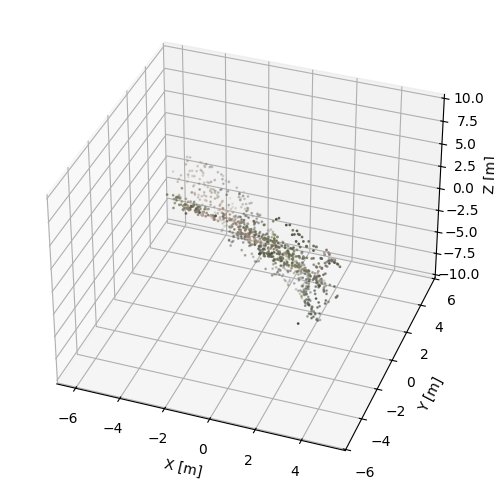

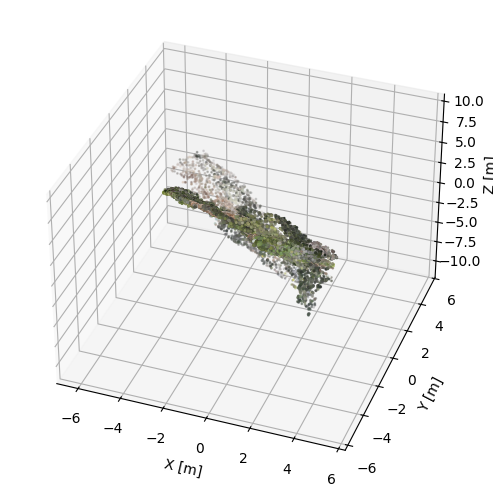

In [6]:
idx = slice(None, None, 100)

# Plotting cloud 1
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": "3d"}, figsize=(7, 5))
sc = ax.scatter(
    x1[idx], y1[idx], z1[idx],
    c=colors1[idx],
    s=1,
    marker='o'
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.view_init(elev=35.0, azim=290.0)
plt.tight_layout()
plt.savefig(f"{log_dir}/PC_Raw_RGB_1.png", dpi=300, bbox_inches="tight")
plt.show()

# Plotting cloud 4
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": "3d"}, figsize=(7, 5))
sc = ax.scatter(
    x4[idx], y4[idx], z4[idx],
    c=colors4[idx],
    s=1,
    marker='o'
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.view_init(elev=35.0, azim=290.0)
plt.tight_layout()
plt.savefig(f"{log_dir}/PC_Raw_RGB_4.png", dpi=300, bbox_inches="tight")
plt.show()

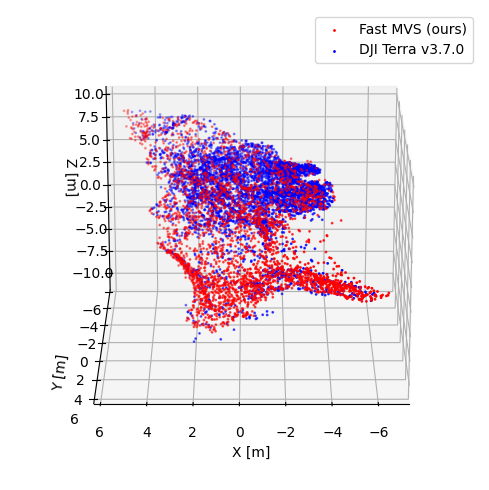

In [7]:
idx = slice(None, None, 30)
idx_2 =  slice(None, None, 500)

# 一个 figure 里画两个点云
fig, ax = plt.subplots(1, 1, subplot_kw={"projection": "3d"}, figsize=(7, 5))

# Cloud 1：红色
ax.scatter(
    x1[idx], y1[idx], z1[idx],
    c='r',          # 固定红色
    s=1,
    marker='o',
    label='Fast MVS (ours)'
)

# Cloud 4：蓝色
ax.scatter(
    x4[idx_2], y4[idx_2], z4[idx_2],
    c='b',          # 固定蓝色
    s=1,
    marker='o',
    label='DJI Terra v3.7.0'
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.view_init(elev=20.0, azim=90.0)

# 可选：加图例方便区分
ax.legend()

plt.tight_layout()
plt.savefig(f"{log_dir}/PC_Raw_RGB_1_4_combined.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
import laspy
import numpy as np

def save_xyzrgb_to_las(x, y, z, colors, out_path):
    """
    x, y, z: 1D numpy arrays, same shape, float 或 double 都行
    colors:  (N, 3) numpy array, 可以是 [0,1] float 或 [0,255]/[0,65535] uint
    """
    assert x.shape == y.shape == z.shape
    assert colors.shape[0] == x.shape[0] and colors.shape[1] == 3

    header = laspy.LasHeader(point_format=3, version="1.2")

    # 设置坐标缩放与偏移
    header.scales = np.array([0.001, 0.001, 0.001])
    header.offsets = np.array([x.min(), y.min(), z.min()])

    las = laspy.LasData(header)

    # 坐标直接塞进去，laspy 会根据 scale/offset 做转换
    las.x = x
    las.y = y
    las.z = z

    # 处理颜色
    cols = colors.copy()

    # 如果是 float 型，假设在 [0,1]，映射到 [0,65535]
    if np.issubdtype(cols.dtype, np.floating):
        cols = np.clip(cols, 0.0, 1.0)
        cols = (cols * 65535.0).astype(np.uint16)
    else:
        max_val = cols.max()
        # 常见情况：0–255 或 0–65535
        if max_val <= 255:
            cols = (cols.astype(np.float32) / 255.0 * 65535.0).astype(np.uint16)
        else:
            cols = cols.astype(np.uint16)

    las.red   = cols[:, 0]
    las.green = cols[:, 1]
    las.blue  = cols[:, 2]

    las.write(out_path)
    print(f"Saved {len(x)} points with color to {out_path}")

#export to las file
save_xyzrgb_to_las(
    cloud4_refined[:, 0],
    cloud4_refined[:, 1],
    cloud4_refined[:, 2],
    colors4,
    f"{log_dir}/Cloud4_refined.las"
)

save_xyzrgb_to_las(
    x1,
    y1,
    z1,
    colors1,
    f"{log_dir}/Cloud1.las"
)

Saved 3066639 points with color to outputs/20251130-1716/Cloud4_refined.las
Saved 91660 points with color to outputs/20251130-1716/Cloud1.las


In [8]:
import numpy as np

def estimate_res_auto(points, target_points_per_cell=5, min_res=None, max_res=None):
    """
    根据点云范围和点数自动估计一个 DEM 分辨率（网格大小，单位米）。
    思路：期望每个格子里大约有 target_points_per_cell 个点。
    """
    x = points[:, 0]
    y = points[:, 1]

    x_min, x_max = x.min(), x.max()
    y_min, y_max = y.min(), y.max()

    area = (x_max - x_min) * (y_max - y_min)  # 点云投影面积（近似）
    n_pts = len(points)

    if area <= 0 or n_pts == 0:
        raise ValueError("点云范围或点数异常，无法自动估计网格大小。")

    # 期望每格 k 个点：k = target_points_per_cell
    # 单个点平均“占用面积” ~ area / n_pts
    # 期望每格面积 ~ k * area / n_pts -> res^2 = k * area / n_pts
    res = np.sqrt(target_points_per_cell * area / n_pts)

    # 可选：限制一个上下界，防止 res 过小或过大
    if min_res is not None:
        res = max(res, min_res)
    if max_res is not None:
        res = min(res, max_res)

    return float(res)


def make_dem(points, res, padding=0.0):
    """
    把散乱点云栅格化成 DEM（均值高程），同时返回格子里的点数。
    """
    x = points[:, 0]
    y = points[:, 1]
    z = points[:, 2]

    x_min, x_max = x.min(), x.max()
    y_min, y_max = y.min(), y.max()

    x_min -= padding
    x_max += padding
    y_min -= padding
    y_max += padding

    nx = int(np.ceil((x_max - x_min) / res))
    ny = int(np.ceil((y_max - y_min) / res))

    x_edges = x_min + np.arange(nx + 1) * res
    y_edges = y_min + np.arange(ny + 1) * res

    sum_z = np.zeros((ny, nx), dtype=np.float64)
    cnt   = np.zeros((ny, nx), dtype=np.int32)

    ix = ((x - x_min) / res).astype(int)
    iy = ((y - y_min) / res).astype(int)

    mask = (ix >= 0) & (ix < nx) & (iy >= 0) & (iy < ny)
    ix = ix[mask]
    iy = iy[mask]
    z  = z[mask]

    np.add.at(sum_z, (iy, ix), z)
    np.add.at(cnt,   (iy, ix), 1)

    dem = np.full((ny, nx), np.nan, dtype=np.float64)
    valid = cnt > 0
    dem[valid] = sum_z[valid] / cnt[valid]

    return dem, cnt, x_edges, y_edges


def dem_volume_single_auto(points,
                           z_ref="min",
                           target_points_per_cell=5,
                           min_res=None,
                           max_res=None):
    """
    自动估计 DEM 网格大小，并计算一个点云的体积和空格子比例。

    参数：
        points: (N, 3) 点云（单位都用米）
        z_ref:
            - "min": 以 DEM 中的最小 z 为基准面
            - 数值: 直接用该 z 作为基准面（例如 0.0）
        target_points_per_cell: 希望每个格子平均有多少点（控制网格粗细）
        min_res, max_res: 可选，强制给 res 一个上下界

    返回：
        volume:      体积（m^3）
        res_used:    实际采用的网格大小（m）
        empty_ratio: 空格子比例（0~1）
    """
    # 1) 自动估计一个 res
    res = estimate_res_auto(points,
                            target_points_per_cell=target_points_per_cell,
                            min_res=min_res,
                            max_res=max_res)

    # 2) 栅格化成 DEM
    dem, cnt, x_edges, y_edges = make_dem(points, res)

    valid = ~np.isnan(dem)
    if not np.any(valid):
        raise ValueError("DEM 中没有有效高度，点云太稀 or 范围有问题。")

    # 3) 基准面
    if z_ref == "min":
        base = np.nanmin(dem)
    else:
        base = float(z_ref)

    dz = dem[valid] - base
    dz_pos = dz[dz > 0.0]

    cell_area = res * res
    volume = np.sum(dz_pos) * cell_area

    # 4) 空格子比例：cnt == 0 的格子占比
    total_cells = cnt.size
    empty_cells = np.count_nonzero(cnt == 0)
    empty_ratio = empty_cells / total_cells

    return volume, res, empty_ratio

In [9]:
target = np.vstack((x4, y4, z4)).T
source = np.vstack((x1, y1, z1)).T

cloud4_refined = source.copy()

In [10]:
V_source, res_src, empty_src = dem_volume_single_auto(
    source,
    z_ref="min",               # 或者换成统一的 0.0 / 某个高程
    target_points_per_cell=100,  # 每格大约 5 个点，按需要调
    min_res=None,              # 不要小于 5 cm，防止太细
    max_res=None               # 也不要粗到离谱
)

V_target, res_tgt, empty_tgt = dem_volume_single_auto(
    target,
    z_ref="min",
    target_points_per_cell=100,
    min_res=None,
    max_res=None
)

print(f"Source: V={V_source:.6f} m^3, res={res_src:.3f} m, empty_ratio={empty_src:.3f}")
print(f"Target: V={V_target:.6f} m^3, res={res_tgt:.3f} m, empty_ratio={empty_tgt:.3f}")

Source: V=621.237183 m^3, res=0.389 m, empty_ratio=0.580
Target: V=532.937468 m^3, res=0.065 m, empty_ratio=0.664


### Change Detection

```bash
git submodule update --init --recursive
cd py4dgeo
python -m pip install -v --editable .
```

In [11]:
# Stable area shapefile
shp_file = "/Users/sam/Desktop/stable.shp"
stable_shp = gpd.read_file(shp_file)

In [17]:
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

def debug_plot_cloud_and_shp(
    cloud: np.ndarray,
    shp: gpd.GeoDataFrame,
    crs_cloud: str,
    sample: int = 5000,
    out_path: str | None = None,
):
    """
    在 2D 平面上可视化点云 XY 和稳定区域多边形，方便检查是否对齐。
    cloud: N x 3 (X, Y, Z) 或 N x >=2
    crs_cloud: 点云的坐标系（例如 'EPSG:32648' 或与 shapefile 一致的 CRS）
    """
    # 1) 点云 -> GeoDataFrame（只用 XY 即可）
    cloud_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(cloud[:, 0], cloud[:, 1]),
        crs=crs_cloud,
    )

    # 2) 把 shapefile 重投影到点云的 CRS
    shp_proj = shp.to_crs(cloud_gdf.crs)

    # 3) 随机抽样一点点云避免太卡
    n = len(cloud_gdf)
    if n > sample:
        cloud_sample = cloud_gdf.sample(sample, random_state=0)
    else:
        cloud_sample = cloud_gdf

    # 4) 画图
    fig, ax = plt.subplots(figsize=(7, 7))
    # 多边形边界：红色
    shp_proj.boundary.plot(ax=ax, edgecolor="red", linewidth=1, alpha=0.8)
    # 点云：蓝色
    cloud_sample.plot(ax=ax, markersize=1, color="blue", alpha=0.5)

    ax.set_aspect("equal")
    ax.set_title("Cloud vs Stable Region (XY)")

    if out_path is not None:
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()

In [12]:
print("X range:", target[:, 0].min(), target[:, 0].max())
print("Y range:", target[:, 1].min(), target[:, 1].max())
print("Z range:", target[:, 2].min(), target[:, 2].max())
print("shp.crs:", stable_shp.crs)
print("shp bounds:", stable_shp.total_bounds)

X range: -6.285474412111938 5.5319060549891965
Y range: -5.6744405608651975 5.450030850246832
Z range: -10.756445582751738 9.767982809732896
shp.crs: EPSG:4326
shp bounds: [-6.52022667e+00 -1.48698291e-03 -1.10397398e+00  5.76243058e+00]


In [13]:
print("行数:", len(stable_shp))
print(stable_shp.head())

print("几何是否为空:", stable_shp.geometry.is_empty)
print("几何是否有效:", stable_shp.geometry.is_valid)
print("是否为 None:", stable_shp.geometry.isna())

行数: 1
   id                                           geometry
0 NaN  POLYGON ((-1.50653 -0.00149, -1.96399 0.43767,...
几何是否为空: 0    False
dtype: bool
几何是否有效: 0    True
dtype: bool
是否为 None: 0    False
Name: geometry, dtype: bool


In [14]:
# 假设你的 shapefile 是 shp，点云是 cloud (N x 3)
print("shp.crs =", stable_shp.crs)

# 比如：shp.crs 是 EPSG:32648，而你的 cloud 其实也是这个坐标系，就这样：
debug_plot_cloud_and_shp(
    cloud=target,
    shp=stable_shp,
    crs_cloud="EPSG:4326",         # 写成你真实的 CRS，不要盲写 4326
    sample=10000,
    out_path="debug_cloud_shp.png",
)

shp.crs = EPSG:4326


NameError: name 'debug_plot_cloud_and_shp' is not defined

In [15]:
stable_before, mask_before = pipeline.isolate_stable(target, stable_shp)
stable_after,  mask_after  = pipeline.isolate_stable(cloud4_refined, stable_shp)

print(f"Stable points in Cloud 1: {stable_before.shape[0]}")
print(f"Stable points in Cloud 4: {stable_after.shape[0]}")

epoch_stable_before = py4dgeo.Epoch(stable_before)
epoch_stable_after  = py4dgeo.Epoch(stable_after)

# C2C distances computation
epoch_stable_after.build_kdtree()
indices, distances = epoch_stable_after.kdtree.nearest_neighbors(
    epoch_stable_before.cloud, 1
)
distances = np.sqrt(distances)

print(f"C2C Median distances: {np.median(distances):.3f} m")
print(f"C2C Std. dev. of distances: {np.std(distances):.3f} m")
print(f"C2C max of distances: {np.max(distances):.3f} m")

Stable points in Cloud 1: 77921
Stable points in Cloud 4: 9364
[2025-12-02 22:46:26][INFO] Building KDTree structure with leaf parameter 10
C2C Median distances: 0.040 m
C2C Std. dev. of distances: 0.054 m
C2C max of distances: 0.538 m


In [16]:
avg_spacing = pipeline.estimate_avg_spacing(target)
print("Estimated average spacing:", avg_spacing)

# Define a target downsampling ratio
ref_ratio = 0.01
init_voxel_size = avg_spacing / ref_ratio

# Adaptively determine the voxel size
adapted_voxel_size = pipeline.adaptive_voxel_size(target, ref_ratio, init_voxel_size, 25, 15, 1)
print("Adapted voxel size:", adapted_voxel_size)

# Downsample using the final voxel size
down_source = pipeline.voxel_downsample(target, adapted_voxel_size)
print(f"Original points: {len(target)}, Downsampled points: {len(down_source)}")

Estimated average spacing: 0.004513920401226883
0.0004705477234196787
Voxel size: 1.1167511809852735, error: 0.009529452276580322, scale: 0.9058427872792182
8.184856450335367e-05
Voxel size: 0.9789140763378373, error: 0.009918151435496646, scale: 0.7741076414422877
0.00010369658769747596
Voxel size: 0.8296621554887227, error: 0.009896303412302524, scale: 0.6086823458745971
0.00014347955530468373
Voxel size: 0.6811142050966926, error: 0.009856520444695316, scale: 0.4113937636677554
0.00020511054610601378
Voxel size: 0.5427566541469304, error: 0.009794889453893986, scale: 0.1843248382697944
0.0003283725277086739
Voxel size: 0.4208765570607856, error: 0.009671627472291326, scale: -0.0699966534177624
0.0005364178829004653
Voxel size: 0.31848125479892186, error: 0.009463582117099535, scale: -0.34877261182653585
0.00093783454785516
Voxel size: 0.23600659697540005, error: 0.00906216545214484, scale: -0.6484764725517659
0.0017129502363988718
Voxel size: 0.17206558420082865, error: 0.0082870497

In [17]:
m3c2 = py4dgeo.M3C2(
    epochs=(epoch_stable_before, epoch_stable_after),
    corepoints=epoch_stable_before.cloud[::],
    normal_radii=(adapted_voxel_size * 2.0,),
    cyl_radius=(adapted_voxel_size),
    max_distance=(15.0),
    registration_error=(0.0),
)
m3c2_distances_stableparts, uncertainties_stableparts = m3c2.run()
reg_target_source = np.nanstd(m3c2_distances_stableparts)

print(f"M3C2 Median distances: {np.nanmedian(m3c2_distances_stableparts):.3f} m")
print(f"M3C2 Std. dev. of distances: {np.nanstd(m3c2_distances_stableparts):.3f} m")
print(f"Registration error {reg_target_source:.3f} m.")

[2025-12-02 22:47:06][INFO] Building KDTree structure with leaf parameter 10


M3C2 Median distances: -0.021 m
M3C2 Std. dev. of distances: 0.044 m
Registration error 0.044 m.


In [26]:
epoch_before = py4dgeo.Epoch(target)
epoch_after = py4dgeo.Epoch(cloud4_refined)

corepoints_pcd        = o3d.geometry.PointCloud()
corepoints_pcd.points = o3d.utility.Vector3dVector(epoch_before.cloud)
corepoints_pcd        = corepoints_pcd.voxel_down_sample(voxel_size=adapted_voxel_size)#0.1)
corepoints            = np.asarray(corepoints_pcd.points)

m3c2 = py4dgeo.M3C2(
    epochs=(epoch_before, epoch_after),
    corepoints=corepoints,
    normal_radii=(adapted_voxel_size * 2.0,),
    cyl_radius=(adapted_voxel_size),
    max_distance=(15.0),
    registration_error=(reg_target_source),
)
m3c2_distances, uncertainties = m3c2.run()
change_sign = np.where(abs(m3c2_distances) > uncertainties["lodetection"], True, False)

[2025-12-03 07:01:00][INFO] Building KDTree structure with leaf parameter 10
[2025-12-03 07:01:02][INFO] Building KDTree structure with leaf parameter 10


In [27]:
import numpy as np

dist = m3c2_distances              # 签名的法向距离
lod  = uncertainties["lodetection"]  # LoD 数组

# 1) 签名距离的 bias / std（看有没有系统偏差）
signed_mean = float(np.mean(dist))
signed_std  = float(np.std(dist))

# 2) 绝对距离的统计（更适合写在表里）
abs_dist = np.abs(dist)
abs_mean = float(np.mean(abs_dist))
p50      = float(np.percentile(abs_dist, 50))
p95      = float(np.percentile(abs_dist, 95))
p99      = float(np.percentile(abs_dist, 99))

# 3) 在某个阈值内的比例，比如 5cm / 10cm
within_5cm  = float(np.mean(abs_dist <= 0.05) * 100.0)   # 单位: %
within_10cm = float(np.mean(abs_dist <= 0.10) * 100.0)   # 单位: %

print(f"N corepoints: {len(dist)}")
print(f"Signed mean = {signed_mean:.4f} m, signed std = {signed_std:.4f} m")
print(f"Abs mean    = {abs_mean:.44f} m, median = {p50:.4f} m")
print(f"P95 = {p95:.4f} m, P99 = {p99:.4f} m")
print(f"Within 5 cm : {within_5cm:.2f} %")
print(f"Within 10 cm: {within_10cm:.2f} %")


N corepoints: 30372
Signed mean = nan m, signed std = nan m
Abs mean    = nan m, median = nan m
P95 = nan m, P99 = nan m
Within 5 cm : 54.43 %
Within 10 cm: 78.07 %


In [28]:
dist = m3c2_distances
lod  = uncertainties["lodetection"]

print("N corepoints:", dist.size)
print("  finite(dist):", np.isfinite(dist).sum())
print("  NaN/Inf(dist):", np.sum(~np.isfinite(dist)))

print("  finite(LoD):", np.isfinite(lod).sum())
print("  NaN/Inf(LoD):", np.sum(~np.isfinite(lod)))


N corepoints: 30372
  finite(dist): 28688
  NaN/Inf(dist): 1684
  finite(LoD): 28429
  NaN/Inf(LoD): 1943


In [29]:
dist = m3c2_distances
lod  = uncertainties["lodetection"]

valid_mask = np.isfinite(dist) & np.isfinite(lod)
dist_valid = dist[valid_mask]
lod_valid  = lod[valid_mask]

print("Valid corepoints:", dist_valid.size, "/", dist.size,
      f"({dist_valid.size / dist.size * 100:.2f}%)")


Valid corepoints: 28429 / 30372 (93.60%)


In [30]:
# 签名距离：看 bias / std
signed_mean = float(np.mean(dist_valid))
signed_std  = float(np.std(dist_valid))

# 绝对值：看误差量级
abs_dist = np.abs(dist_valid)
abs_mean = float(np.mean(abs_dist))
p50      = float(np.percentile(abs_dist, 50))
p95      = float(np.percentile(abs_dist, 95))
p99      = float(np.percentile(abs_dist, 99))

within_5cm  = float(np.mean(abs_dist <= 0.05) * 100.0)
within_10cm = float(np.mean(abs_dist <= 0.10) * 100.0)

print(f"Signed mean = {signed_mean:.4f} m, signed std = {signed_std:.4f} m")
print(f"Abs mean    = {abs_mean:.4f} m, median = {p50:.4f} m")
print(f"P95 = {p95:.4f} m, P99 = {p99:.4f} m")
print(f"Within 5 cm  (valid-only): {within_5cm:.2f} %")
print(f"Within 10 cm (valid-only): {within_10cm:.2f} %")


Signed mean = -0.0334 m, signed std = 0.3082 m
Abs mean    = 0.0936 m, median = 0.0413 m
P95 = 0.2333 m, P99 = 1.3097 m
Within 5 cm  (valid-only): 57.83 %
Within 10 cm (valid-only): 82.83 %


In [31]:
rmse = float(np.sqrt(np.mean(dist_valid**2)))
print("RMSE (normal-aligned):", rmse, "m")


RMSE (normal-aligned): 0.30999200251860726 m


In [34]:
import numpy as np

dist = m3c2_distances  # 正负都有的 normal-aligned distance
valid = np.isfinite(dist)
dist_valid = dist[valid]

rmse_all = float(np.sqrt(np.mean(dist_valid**2)))

abs_valid = np.abs(dist_valid)
p95 = float(np.quantile(abs_valid, 0.95))
central = abs_valid <= p95
rmse_95 = float(np.sqrt(np.mean(dist_valid[central]**2)))

print("RMSE (all):", rmse_all)
print("RMSE (central 95%):", rmse_95)


RMSE (all): 0.30933169460643173
RMSE (central 95%): 0.06802490729118464


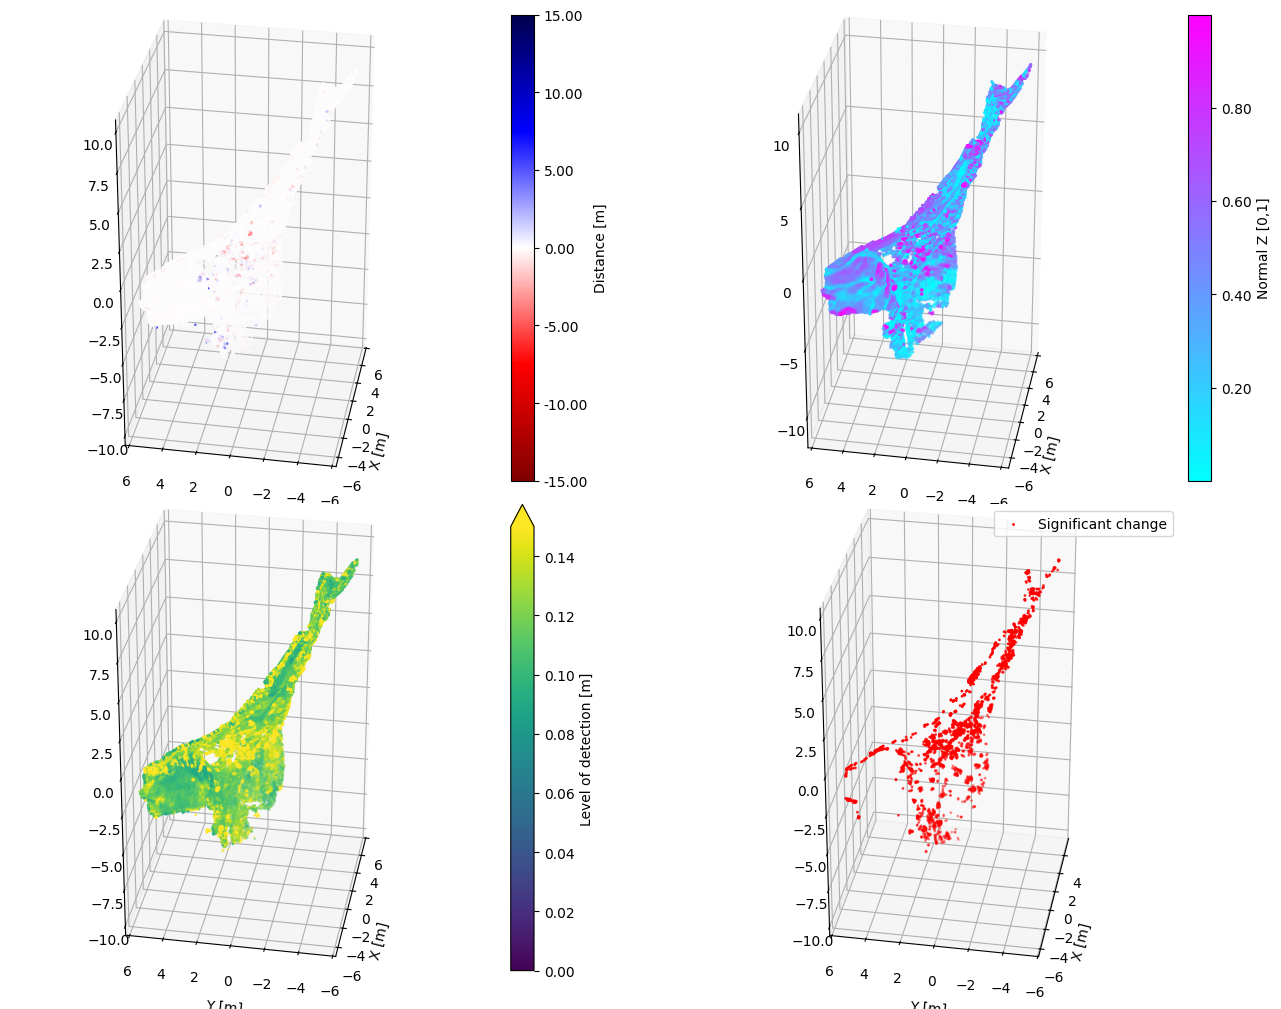

In [19]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10), subplot_kw={"projection": "3d"})
(ax1, ax2), (ax3, ax4) = axs

# Plot the distances
d = ax1.scatter(
    corepoints[:, 0],
    corepoints[:, 1],
    corepoints[:, 2],
    c=m3c2_distances,
    cmap="seismic_r",
    vmin=-15.0,
    vmax=15.0,
    s=1,
    marker='*',
)
plt.colorbar(d, format=("%.2f"), label="Distance [m]", ax=ax1)

# Plot the directions
directions = m3c2.directions()
dz = ax2.scatter(
    corepoints[:, 0],
    corepoints[:, 1],
    corepoints[:, 2],
    c=directions[:, 2],
    cmap="cool",
    s=1,
)
plt.colorbar(dz, format=("%.2f"), label="Normal Z [0,1]", ax=ax2)

# Plot the level of detection values
l = ax3.scatter(
    corepoints[:, 0],
    corepoints[:, 1],
    corepoints[:, 2],
    c=uncertainties["lodetection"],
    cmap="viridis",
    vmin=0.0,
    vmax=0.15,
    s=1,
)
plt.colorbar(
    l,
    format=("%.2f"),
    label="Level of detection [m]",
    ax=ax3,
    extend="max",
)

# Plot the significant change values (boolean)
ax4.scatter(
    corepoints[change_sign][:, 0],
    corepoints[change_sign][:, 1],
    corepoints[change_sign][:, 2],
    label="Significant change",
    c="red",
    s=1,
)
ax4.legend()

# Add plot elements
for ax_set in axs:
    for ax in ax_set:
        ax.set_xlabel("X [m]")
        ax.set_ylabel("Y [m]")
        ax.set_aspect("equal")
        ax.view_init(elev=30.0, azim=190.0)

plt.axis("equal")
plt.tight_layout()
plt.savefig(f"{log_dir}/PC_changedet.png", dpi=300, bbox_inches="tight")
plt.show()

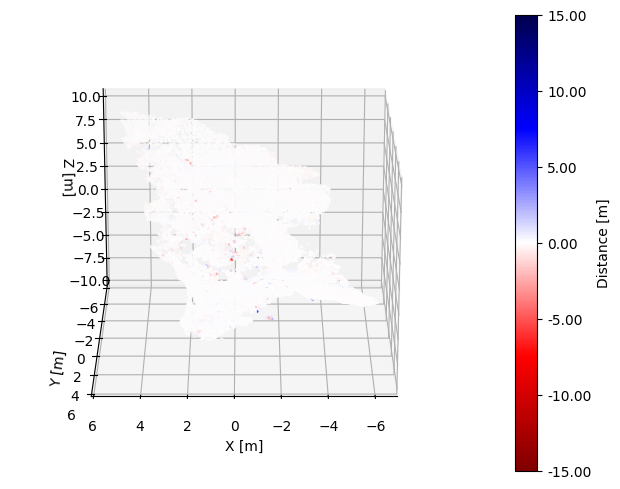

In [20]:
import matplotlib.pyplot as plt

# 单独保存“距离”这一幅图
fig, ax = plt.subplots(1, 1, figsize=(10, 5), subplot_kw={"projection": "3d"})

d = ax.scatter(
    corepoints[:, 0],
    corepoints[:, 1],
    corepoints[:, 2],
    c=m3c2_distances,
    cmap="seismic_r",
    vmin=-15.0,
    vmax=15.0,
    s=1,
    marker="*",
)

cbar = plt.colorbar(d, ax=ax, format="%.2f")
cbar.set_label("Distance [m]")

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")  # 需要的话可加 / 可删

# 视角和原来保持一致
ax.view_init(elev=20.0, azim=90.0)

# 3D 里 set_aspect("equal") 不怎么好使，可以视情况要不要
# ax.set_aspect("auto")

fig.tight_layout()
fig.savefig(f"{log_dir}/PC_changedet_ax1.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

### Volume Calculation

In [21]:
hulls = pipeline.segment_changes(corepoints, change_sign)

selected_indices    = [np.argmax([hull.area for hull in hulls])]
selected_hulls      = [hulls[i] for i in selected_indices]
inside_mask_refined = pipeline.is_inside_selected_hulls_vectorized(selected_hulls, cloud4_refined[:, :2])
inside_mask_raw     = pipeline.is_inside_selected_hulls_vectorized(selected_hulls, target[:, :2])

filtered_refined = cloud4_refined[inside_mask_refined]
filtered_raw     = target[inside_mask_raw]

filtered_refined_x, filtered_refined_y, filtered_refined_z = filtered_refined.T
filtered_raw_x, filtered_raw_y, filtered_raw_z = filtered_raw.T

In [32]:
dem_before, dem_after, dem_grid_x, dem_grid_y, grid_res = pipeline.reletive_DEM(
    filtered_raw,
    filtered_refined,
    grid_res=None,
    method="linear",
    mask_hulls=selected_hulls,
)

net_volume, cut_volume, fill_volume, diff_DEMs = pipeline.calculate_volume(
    dem_before, dem_after, grid_res=grid_res, threshold=reg_target_source
)

DEM1 NaN ratio: 44.44%
DEM2 NaN ratio: 48.61%
Cells with data on only one DEM: 6 (4.17% of grid)


In [33]:
print("Cut Volume (removed): {} m³".format(cut_volume))
print("Fill Volume (added): {} m³".format(fill_volume))
print("Net Volume Change: {} m³".format(net_volume))
print(grid_res)

Cut Volume (removed): 6.420629760925967e-05 m³
Fill Volume (added): 0.004947925721247679 m³
Net Volume Change: 0.004883719423638419 m³
0.007231144381346052


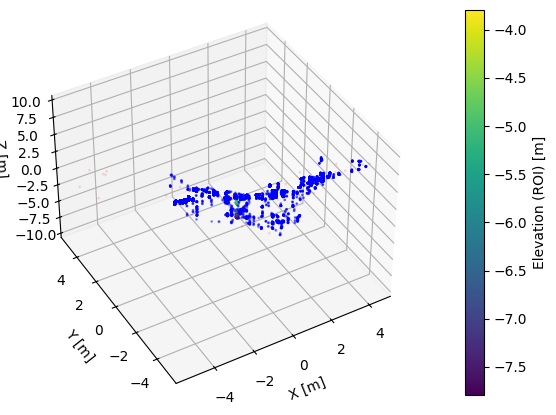

In [50]:
unselected_hulls = [
    hulls[i] for i in range(len(hulls)) if i not in selected_indices
]
inside_nonroi_raw = pipeline.is_inside_selected_hulls_vectorized(
    unselected_hulls, target[:, :2]
)

mask_combined = np.logical_and(~inside_nonroi_raw, ~inside_mask_raw)
unfiltered_raw = target[mask_combined]

filtered_raw_nonroi   = target[inside_nonroi_raw]
filtered_raw_nonroi_x = filtered_raw_nonroi[:, 0]
filtered_raw_nonroi_y = filtered_raw_nonroi[:, 1]
filtered_raw_nonroi_z = filtered_raw_nonroi[:, 2]

fig, ax = plt.subplots(1, 1, subplot_kw={"projection": "3d"}, figsize=(7, 5))

unfiltered_raw_pcd        = o3d.geometry.PointCloud()
unfiltered_raw_pcd.points = o3d.utility.Vector3dVector(unfiltered_raw)
unfiltered_raw_pcd        = unfiltered_raw_pcd.voxel_down_sample(voxel_size=4)
unfiltered_raw_ds         = np.asarray(unfiltered_raw_pcd.points)

unfiltered_raw_x = unfiltered_raw_ds[:, 0]
unfiltered_raw_y = unfiltered_raw_ds[:, 1]
unfiltered_raw_z = unfiltered_raw_ds[:, 2]

scatter_unaffected = ax.scatter(
    filtered_raw_x[::1],
    filtered_raw_y[::1],
    filtered_raw_z[::1],
    c=filtered_raw_z[::1],
    cmap="viridis",
    s=1,
    marker="o",
)
scatter_affected = ax.scatter(
    unfiltered_raw_x[::1],
    unfiltered_raw_y[::1],
    unfiltered_raw_z[::1],
    c="red",
    s=1,
    marker="o",
    alpha=0.1,
)
scatter_unselect = ax.scatter(
    filtered_raw_nonroi_x[::1],
    filtered_raw_nonroi_y[::1],
    filtered_raw_nonroi_z[::1],
    c="blue",
    s=1,
    marker="o",
)

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.view_init(elev=40.0, azim=240.0)

cbar = plt.colorbar(scatter_unaffected, ax=ax, pad=0.1)
cbar.set_label("Elevation (ROI) [m]")

plt.savefig(f"{log_dir}/ROI.png", dpi=300, bbox_inches="tight")
plt.show()

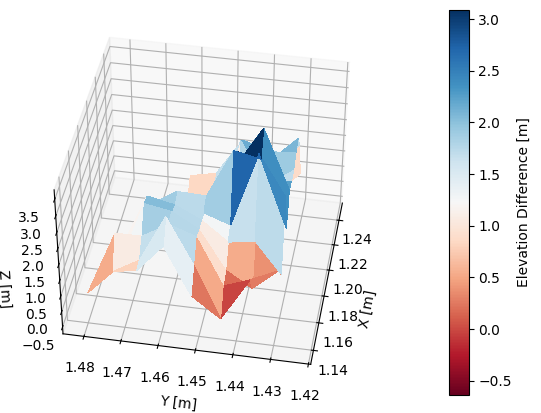

In [51]:
diff_masked = np.ma.masked_invalid(diff_DEMs)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    dem_grid_x, dem_grid_y, diff_masked, cmap="RdBu", linewidth=0, antialiased=False
)

fig.colorbar(surf, ax=ax, pad=0.1, label="Elevation Difference [m]")

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.view_init(elev=40.0, azim=190.0)

plt.savefig(f"{log_dir}/PC_DEM_3D.png", dpi=300, bbox_inches="tight")
plt.show()